# MFCK – validation of `predict_level_covariances`

Figures validating the posterior covariance between fidelity levels of the MFCK
surrogate model, in two test cases:

1. **Sasena (2002), positive autoregressive coefficient** – the covariance is
   consistent with `predict_variances`, and the LF/HF correlation vanishes at
   sampled inputs.
2. **Forrester with a negated LF level, negative autoregressive coefficient** – the
   LF level still improves the HF prediction, the cross-level correlation is
   negative, and its absolute value is the relevant weight.

Both parts share the same figure style and helpers (first two code cells). Part 2
redefines the problem variables (`x`, `bounds`, `xt`, `yt`, ...), so run the
notebook from top to bottom.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# ---- shared figure style (identical for every figure) ----------------------
# Colours are tied to entities, never to rank: LF = orange, HF = blue,
# cross-level quantity (LF/HF) = aqua.
C_LF, C_HF, C_X = "#eb6834", "#2a78d6", "#1baf7a"
INK, INK_2, GRID = "#0b0b0b", "#52514e", "#d9d8d4"

plt.rcParams.update({
    "figure.dpi": 150,
    "savefig.dpi": 300,
    "savefig.bbox": "tight",
    "font.size": 10,
    "axes.titlesize": 11,
    "axes.titleweight": "bold",
    "axes.labelsize": 10,
    "axes.labelcolor": INK_2,
    "axes.edgecolor": INK_2,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": GRID,
    "grid.linewidth": 0.6,
    "xtick.color": INK_2,
    "ytick.color": INK_2,
    "lines.linewidth": 1.1,
    "axes.linewidth": 0.7,
    "xtick.major.width": 0.7,
    "ytick.major.width": 0.7,
    "legend.frameon": True,
    "legend.framealpha": 0.75,
    "legend.facecolor": "white",
    "legend.edgecolor": GRID,
    "legend.fancybox": False,
    "legend.borderpad": 0.4,
    "legend.fontsize": 8,
    "figure.constrained_layout.use": True,
})
PANEL_W, PANEL_H = 5.2, 4.0      # size of one panel, same for every figure


def new_figure(ncols=1, suptitle=None):
    fig, axes = plt.subplots(1, ncols, figsize=(PANEL_W * ncols, PANEL_H), squeeze=False)
    if suptitle:
        fig.suptitle(suptitle, fontsize=12, fontweight="bold")
    return fig, axes.ravel()


def finish_axis(ax, title, xlabel="Input $x$", ylabel=None, legend=True, ncol=2):
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    if ylabel:
        ax.set_ylabel(ylabel)
    ax.set_xlim(bounds[0, 0], bounds[0, 1])
    if legend:
        # reserve a free band at the top of the axes for the legend, so that it
        # sits inside the plot (on a translucent background) without hiding data
        n = len(ax.get_legend_handles_labels()[0])
        rows = -(-n // ncol)
        lo, hi = ax.get_ylim()
        ax.set_ylim(lo, hi + (0.07 * rows + 0.04) * (hi - lo))
        ax.legend(loc="upper center", ncol=ncol)


def plot_samples(ax, lf=True, hf=True):
    """LF/HF training samples, same markers in every figure that shows them."""
    if lf:
        ax.scatter(xt[0], yt[0], marker="o", s=26, color=C_LF, edgecolor="white",
                   linewidth=0.5, zorder=4, label="LF samples")
    if hf:
        ax.scatter(xt[1], yt[1], marker="s", s=30, color=C_HF, edgecolor="white",
                   linewidth=0.5, zorder=5, label="HF samples")


def plot_sample_locations(ax):
    """Vertical guides at the sampled inputs (for figures without y data)."""
    for x, c, name in zip(xt, (C_LF, C_HF), ("LF", "HF")):
        for j, xi in enumerate(np.ravel(x)):
            ax.axvline(xi, color=c, lw=0.7, ls=":", alpha=0.7,
                       label=f"{name} sample locations" if j == 0 else None)

The correlation helper is shared by both parts.

In [2]:
def level_correlation(model, X, eps=1e-8):
    """rho(x) = cov_10 / sqrt(cov_00 cov_11); set to 0 where a variance is below eps."""
    c00 = model.predict_level_covariances(X, lvli=0, lvlj=0).ravel()
    c10 = model.predict_level_covariances(X, lvli=1, lvlj=0).ravel()
    c11 = model.predict_level_covariances(X, lvli=1, lvlj=1).ravel()
    ok = (c00 > eps) & (c11 > eps)
    rho = np.zeros_like(c10)
    rho[ok] = c10[ok] / np.sqrt(c00[ok] * c11[ok])
    return c00, c10, c11, np.clip(rho, -1, 1)

# Part 1 – Sasena (2002) test case: positive correlation

### 1.1 Test problem and training data

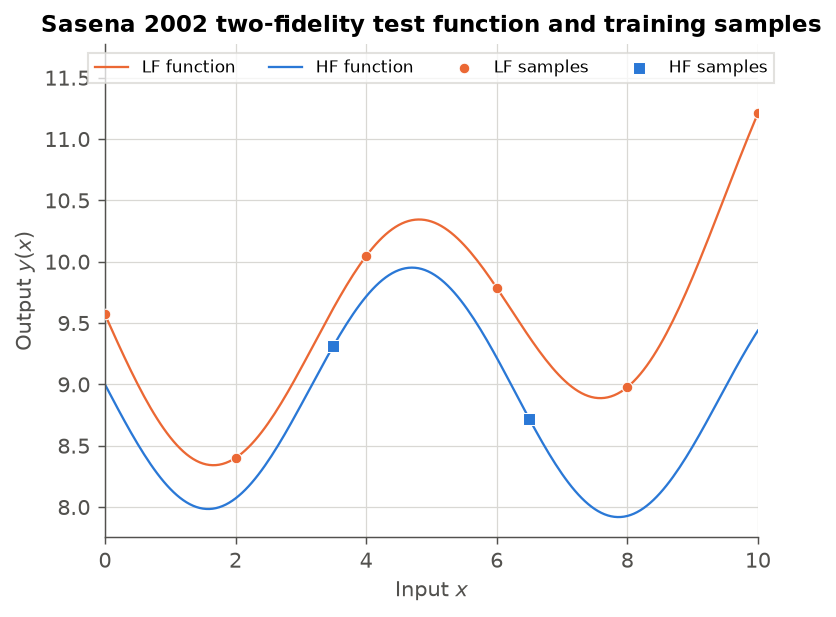

In [3]:
# high-fidelity function
def sasena2002_hf(x):
    return -np.sin(x) - np.exp(x / 100) + 10

# low-fidelity function
def sasena2002_lf(x):
    return sasena2002_hf(x) + 0.3 + 0.03 * (x - 3) ** 2

bounds = np.array([[0, 10]])

x_valid = np.linspace(bounds[0, 0], bounds[0, 1], 201)
X_valid = x_valid.reshape(-1, 1)
y_hf = sasena2002_hf(x_valid)
y_lf = sasena2002_lf(x_valid)

functions = [sasena2002_lf, sasena2002_hf]

xt = [
    np.array([0., 2, 4, 6, 8, 10]),   # LF samples
    np.array([3.5, 6.5]),             # HF samples
]
yt = [f(x) for f, x in zip(functions, xt)]

fig, (ax,) = new_figure()
ax.plot(x_valid, y_lf, color=C_LF, label="LF function")
ax.plot(x_valid, y_hf, color=C_HF, label="HF function")
plot_samples(ax)
finish_axis(ax, "Sasena 2002 two-fidelity test function and training samples",
            ylabel="Output $y(x)$", ncol=4)
plt.show()

### 1.2 Train the MFCK model

In [4]:
from smt.applications import MFCK

sm = MFCK(print_global=False, hyper_opt="Cobyla", n_start=3)

sm.set_training_values(xt[0].reshape(-1, 1), yt[0].reshape(-1, 1), name=0)
sm.set_training_values(xt[1].reshape(-1, 1), yt[1].reshape(-1, 1))

sm.train()

### 1.3 HF prediction uncertainty: `predict_variances` vs `predict_level_covariances`

For the highest level, `predict_level_covariances(X, 1, 1)` must reproduce
`predict_variances(X)`. Panels (a) and (b) show the $\pm 1\sigma$ band obtained
from each method; panel (c) overlays the two variances.

max |difference| between the two variances: 0.0


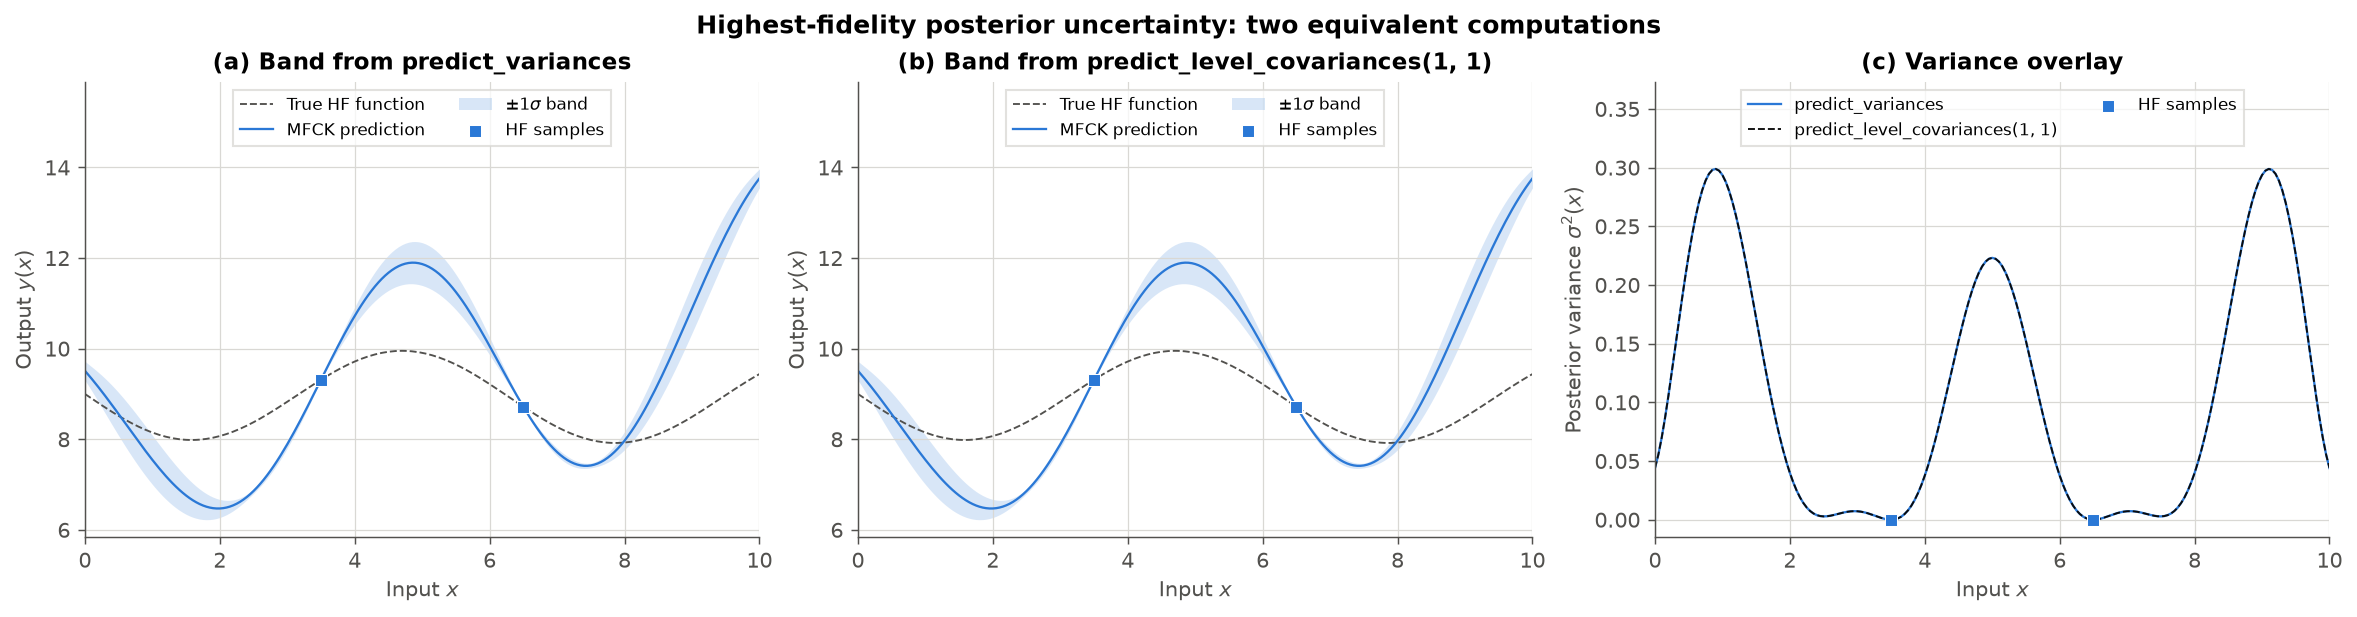

In [5]:
y_pred = sm.predict_values(X_valid).ravel()
s2_var = sm.predict_variances(X_valid).ravel()
s2_cov = sm.predict_level_covariances(X_valid, lvli=1, lvlj=1).ravel()

fig, ax = new_figure(3, "Highest-fidelity posterior uncertainty: two equivalent computations")

for a, s2, title in (
    (ax[0], s2_var, "(a) Band from predict_variances"),
    (ax[1], s2_cov, "(b) Band from predict_level_covariances(1, 1)"),
):
    sd = np.sqrt(np.clip(s2, 0, None))
    a.plot(x_valid, y_hf, color=INK_2, ls="--", lw=0.9, label="True HF function")
    a.plot(x_valid, y_pred, color=C_HF, label="MFCK prediction")
    a.fill_between(x_valid, y_pred - sd, y_pred + sd, color=C_HF, alpha=0.18,
                   linewidth=0, label=r"$\pm 1\sigma$ band")
    a.scatter(xt[1], yt[1], marker="s", s=30, color=C_HF, edgecolor="white",
              linewidth=0.5, zorder=5, label="HF samples")
    finish_axis(a, title, ylabel="Output $y(x)$")

ax[1].sharey(ax[0])
ax[2].plot(x_valid, s2_var, color=C_HF, label="predict_variances")
ax[2].plot(x_valid, s2_cov, color=INK, ls="--", lw=0.9,
           label="predict_level_covariances(1, 1)")
ax[2].scatter(xt[1], np.zeros_like(xt[1]), marker="s", s=30, color=C_HF,
              edgecolor="white", linewidth=0.5, zorder=5, clip_on=False,
              label="HF samples")
finish_axis(ax[2], "(c) Variance overlay", ylabel=r"Posterior variance $\sigma^2(x)$")
print("max |difference| between the two variances:", np.max(np.abs(s2_var - s2_cov)))
plt.show()

### 1.4 Covariances and correlation between fidelity levels

Left: posterior (co)variances of the latent LF and HF functions. Right: the
correlation $\rho(x) = \mathrm{cov}_{01}(x)\,/\,\sqrt{\mathrm{cov}_{00}(x)\,\mathrm{cov}_{11}(x)}$,
set to 0 where either variance is numerically zero (below $10^{-8}$). It must
vanish at every location where the LF or the HF level is already sampled; the
markers in panel (b) show $\rho_{10}$ evaluated exactly at those inputs. Between
samples $\rho_{10}$ can take either sign, and approaches $\pm 1$ right next to a
sampled input, where both residual uncertainties are driven by the same data.

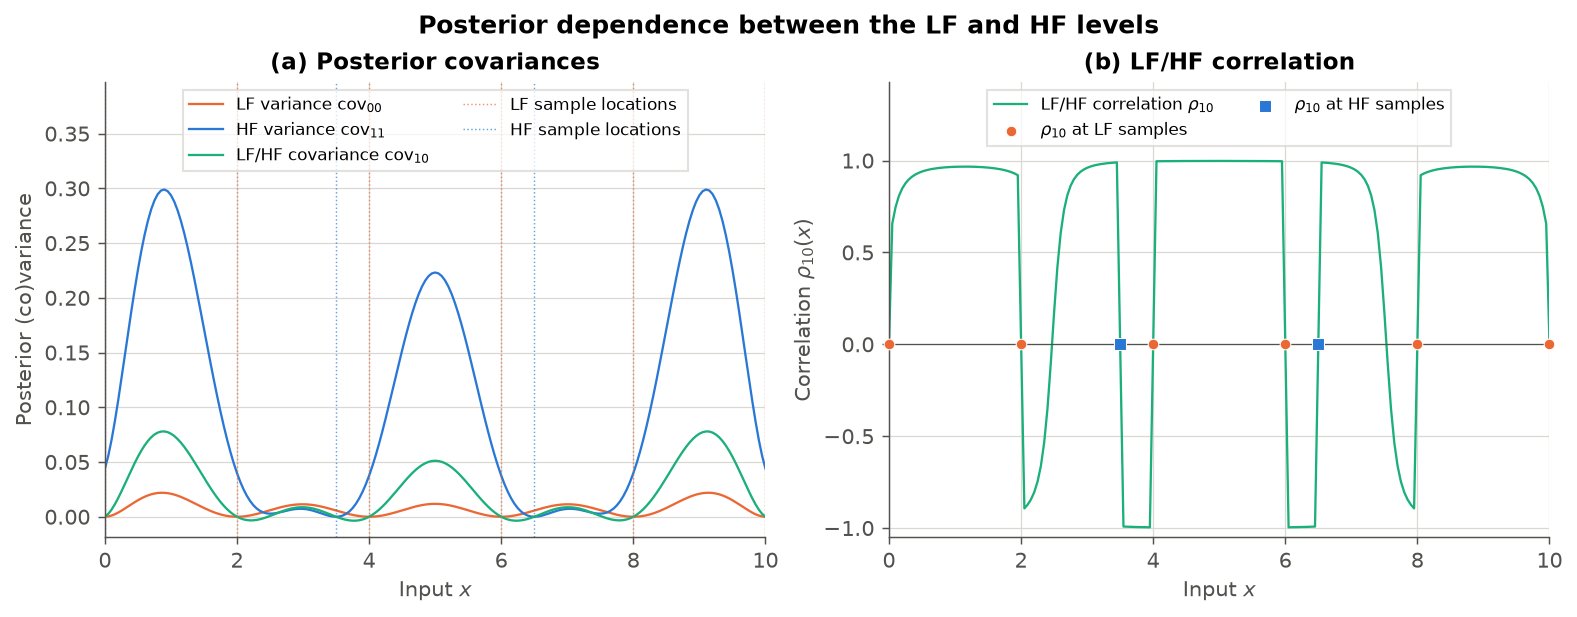

In [6]:
cov_00, cov_10, cov_11, corr_10 = level_correlation(sm, X_valid)
# correlation evaluated exactly at the sampled inputs
rho_lf = level_correlation(sm, xt[0].reshape(-1, 1))[-1]
rho_hf = level_correlation(sm, xt[1].reshape(-1, 1))[-1]

fig, ax = new_figure(2, "Posterior dependence between the LF and HF levels")

ax[0].plot(x_valid, cov_00, color=C_LF, label=r"LF variance $\mathrm{cov}_{00}$")
ax[0].plot(x_valid, cov_11, color=C_HF, label=r"HF variance $\mathrm{cov}_{11}$")
ax[0].plot(x_valid, cov_10, color=C_X, label=r"LF/HF covariance $\mathrm{cov}_{10}$")
plot_sample_locations(ax[0])
finish_axis(ax[0], "(a) Posterior covariances", ylabel="Posterior (co)variance")

ax[1].plot(x_valid, corr_10, color=C_X, label=r"LF/HF correlation $\rho_{10}$")
ax[1].scatter(xt[0], rho_lf, marker="o", s=26, color=C_LF, edgecolor="white",
              linewidth=0.5, zorder=4, clip_on=False, label=r"$\rho_{10}$ at LF samples")
ax[1].scatter(xt[1], rho_hf, marker="s", s=30, color=C_HF, edgecolor="white",
              linewidth=0.5, zorder=5, clip_on=False, label=r"$\rho_{10}$ at HF samples")
ax[1].axhline(0, color=INK_2, lw=0.6)
ax[1].set_ylim(-1.05, 1.05)
finish_axis(ax[1], "(b) LF/HF correlation", ylabel=r"Correlation $\rho_{10}(x)$")
plt.show()

# Part 2 – Forrester with a negated LF level: negative correlation

The MFCK model is autoregressive, $f_{HF}(x) = \rho\, f_{LF}(x) + \delta(x)$, and
$\rho$ can be negative. Here the LF level is exactly the negated HF function, so
the fitted $\rho$ is negative. Two things are checked:

1. the LF level still improves the HF prediction, even though it is anti-correlated;
2. the posterior LF/HF correlation is negative, so `abs(corr)` is the quantity to
   use when the correlation weights an acquisition function.

### 2.1 Test problem and training data

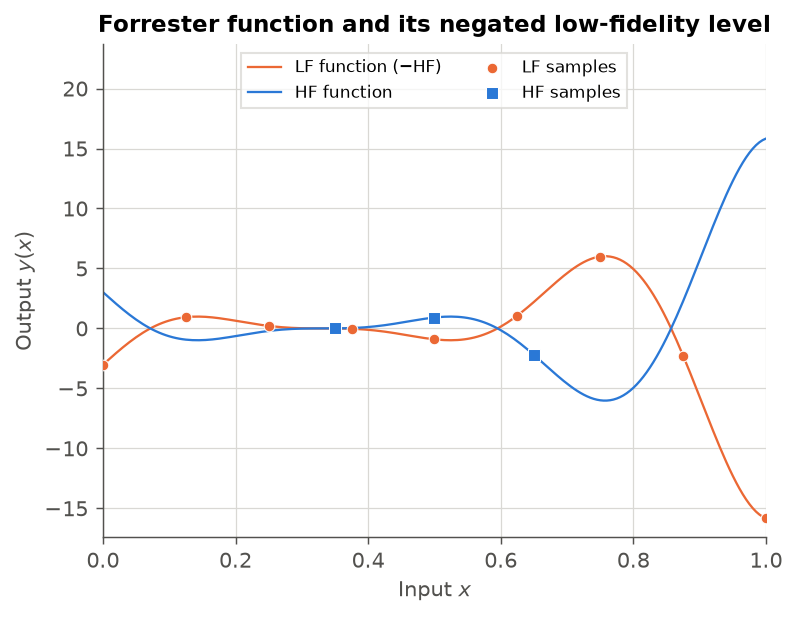

In [7]:
def forrester_hf(x):
    return ((x * 6 - 2) ** 2) * np.sin((x * 6 - 2) * 2)


def neg_forrester_hf(x):
    """LF level: exactly anti-correlated with the HF function (rho = -1)."""
    return -forrester_hf(x)


bounds = np.array([[0.0, 1.0]])

x = np.linspace(bounds[0, 0], bounds[0, 1], 201)
X = x.reshape(-1, 1)
y_hf = forrester_hf(x)
y_lf = neg_forrester_hf(x)

xt = [
    np.linspace(0, 1, 9).reshape(-1, 1),          # LF samples
    np.array([[0.35, 0.5, 0.65]]).reshape(-1, 1),  # HF samples
]
yt = [
    neg_forrester_hf(xt[0]),
    forrester_hf(xt[1]),
]

fig, (ax,) = new_figure()
ax.plot(x, y_lf, color=C_LF, label=r"LF function ($-$HF)")
ax.plot(x, y_hf, color=C_HF, label="HF function")
plot_samples(ax)
finish_axis(ax, "Forrester function and its negated low-fidelity level",
            ylabel="Output $y(x)$")
plt.show()

### 2.2 Train the models

In [8]:
from smt.surrogate_models import KRG
from smt.applications import MFCK

# HF data only: ordinary kriging, and MFCK reduced to a single level
krg = KRG(print_global=False)
krg.set_training_values(xt[1], yt[1])
krg.train()

mfck_sf = MFCK(print_global=False)
mfck_sf.set_training_values(xt[1], yt[1])
mfck_sf.train()

# LF + HF data: two-level MFCK
mfck = MFCK(print_global=False)
mfck.set_training_values(xt[0], yt[0], name=0)
mfck.set_training_values(xt[1], yt[1])
mfck.train()

# fitted autoregressive coefficient rho (kernel layout: sigma_0, l_0, then
# [sigma_k, l_k, rho_k] for each additional level)
kernel_params = mfck._get_kernel_params()
rho_fit = float(np.ravel(kernel_params[2 + 2 * mfck.nx :: mfck.nx + 2])[0])
print(f"fitted rho = {rho_fit:.3f}")

fitted rho = -0.984


### 2.3 Does an anti-correlated LF level still help?

HF prediction with HF data only (a, b) and with both levels (c). The RMSE is
computed against the true HF function on the plotting grid.

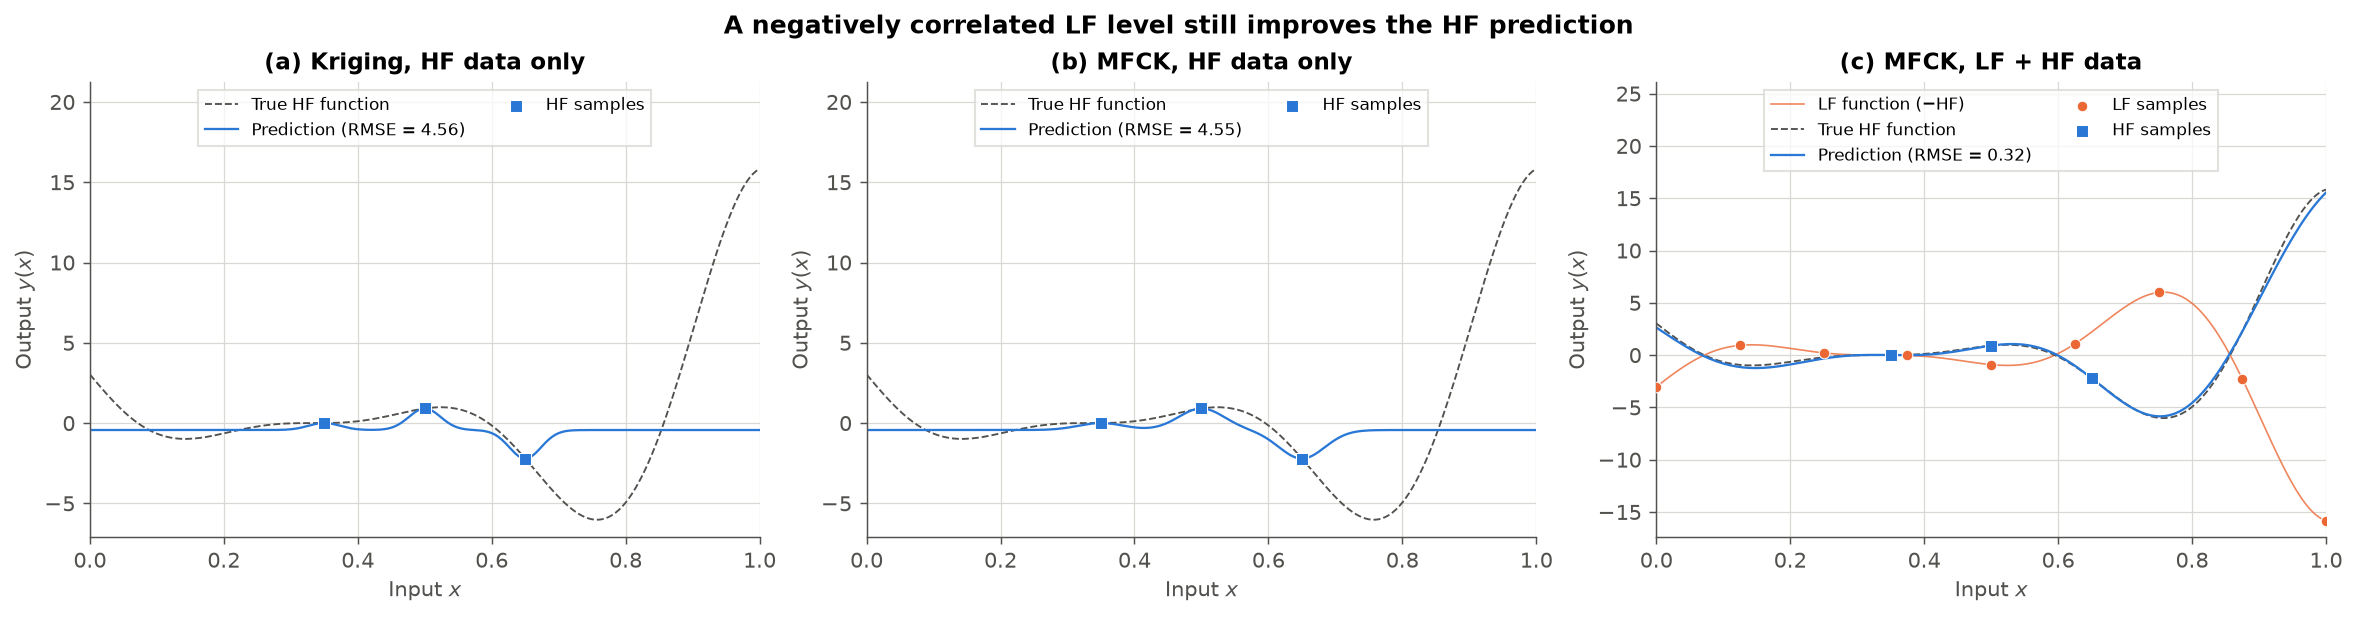

In [9]:
def rmse(y_pred):
    return float(np.sqrt(np.mean((np.ravel(y_pred) - y_hf) ** 2)))


models = (
    (krg, "(a) Kriging, HF data only", False),
    (mfck_sf, "(b) MFCK, HF data only", False),
    (mfck, "(c) MFCK, LF + HF data", True),
)

fig, ax = new_figure(3, "A negatively correlated LF level still improves the HF prediction")

for a, (model, title, uses_lf) in zip(ax, models):
    y_pred = model.predict_values(X).ravel()
    if uses_lf:
        a.plot(x, y_lf, color=C_LF, lw=0.8, alpha=0.8, label=r"LF function ($-$HF)")
    a.plot(x, y_hf, color=INK_2, ls="--", lw=0.9, label="True HF function")
    a.plot(x, y_pred, color=C_HF, label=f"Prediction (RMSE = {rmse(y_pred):.2f})")
    plot_samples(a, lf=uses_lf)
    finish_axis(a, title, ylabel="Output $y(x)$")
    a.set_ylim(top=None)
plt.show()

### 2.4 Posterior covariances and correlation between levels

Left: posterior (co)variances of the latent LF and HF functions. Right: the
correlation $\rho_{10}(x) = \mathrm{cov}_{10}(x)\,/\,\sqrt{\mathrm{cov}_{00}(x)\,\mathrm{cov}_{11}(x)}$,
set to 0 where either variance is numerically zero (below $10^{-8}$), together
with its absolute value. With a negative autoregressive coefficient the
cross-level covariance, and therefore $\rho_{10}$, is negative: $|\rho_{10}|$ is
the quantity measuring how much the LF level informs the HF level.

The LF level is sampled at 9 points only. With a much denser LF design the LF
function is essentially known everywhere, its posterior variance vanishes, and
so does the correlation (nothing is left to correlate with the HF uncertainty).

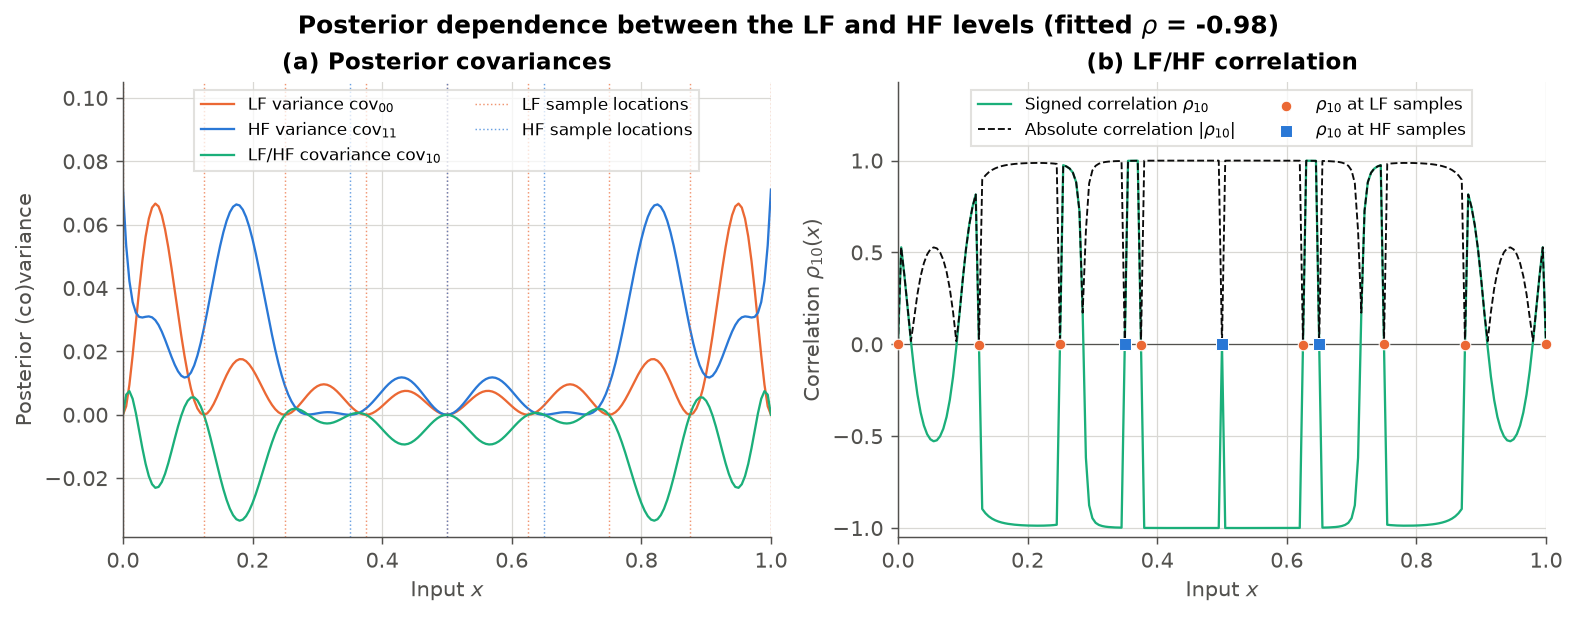

In [10]:
c00, c10, c11, rho = level_correlation(mfck, X)
# correlation evaluated exactly at the sampled inputs
rho_lf = level_correlation(mfck, xt[0])[-1]
rho_hf = level_correlation(mfck, xt[1])[-1]

fig, ax = new_figure(
    2, rf"Posterior dependence between the LF and HF levels (fitted $\rho$ = {rho_fit:.2f})"
)

ax[0].plot(x, c00, color=C_LF, label=r"LF variance $\mathrm{cov}_{00}$")
ax[0].plot(x, c11, color=C_HF, label=r"HF variance $\mathrm{cov}_{11}$")
ax[0].plot(x, c10, color=C_X, label=r"LF/HF covariance $\mathrm{cov}_{10}$")
plot_sample_locations(ax[0])
finish_axis(ax[0], "(a) Posterior covariances", ylabel="Posterior (co)variance")

ax[1].axhline(0, color=INK_2, lw=0.6)
ax[1].plot(x, rho, color=C_X, label=r"Signed correlation $\rho_{10}$")
ax[1].plot(x, np.abs(rho), color=INK, ls="--", lw=0.9, label=r"Absolute correlation $|\rho_{10}|$")
ax[1].scatter(xt[0], rho_lf, marker="o", s=26, color=C_LF, edgecolor="white",
              linewidth=0.5, zorder=4, clip_on=False, label=r"$\rho_{10}$ at LF samples")
ax[1].scatter(xt[1], rho_hf, marker="s", s=30, color=C_HF, edgecolor="white",
              linewidth=0.5, zorder=5, clip_on=False, label=r"$\rho_{10}$ at HF samples")
ax[1].set_ylim(-1.05, 1.05)
finish_axis(ax[1], "(b) LF/HF correlation", ylabel=r"Correlation $\rho_{10}(x)$")
plt.show()